Total de locais candidatos: 15
Geração 1: Melhor fitness = 7540.19
Geração 2: Melhor fitness = 7364.66
Geração 3: Melhor fitness = 7364.66
Geração 4: Melhor fitness = 7364.66
Geração 5: Melhor fitness = 7364.66
Geração 6: Melhor fitness = 7364.66
Geração 7: Melhor fitness = 7364.66
Geração 8: Melhor fitness = 7364.66
Geração 9: Melhor fitness = 7364.66
Geração 10: Melhor fitness = 7364.66
Geração 11: Melhor fitness = 7364.66
Geração 12: Melhor fitness = 7364.66
Geração 13: Melhor fitness = 7364.66
Geração 14: Melhor fitness = 7364.66
Geração 15: Melhor fitness = 7364.66
Geração 16: Melhor fitness = 7364.66
Geração 17: Melhor fitness = 7364.66
Geração 18: Melhor fitness = 7364.66
Geração 19: Melhor fitness = 7364.66
Geração 20: Melhor fitness = 7364.66
Geração 21: Melhor fitness = 7364.66
Geração 22: Melhor fitness = 7364.66
Geração 23: Melhor fitness = 7364.66
Geração 24: Melhor fitness = 7364.66
Geração 25: Melhor fitness = 7364.66
Geração 26: Melhor fitness = 7364.66
Geração 27: Melh

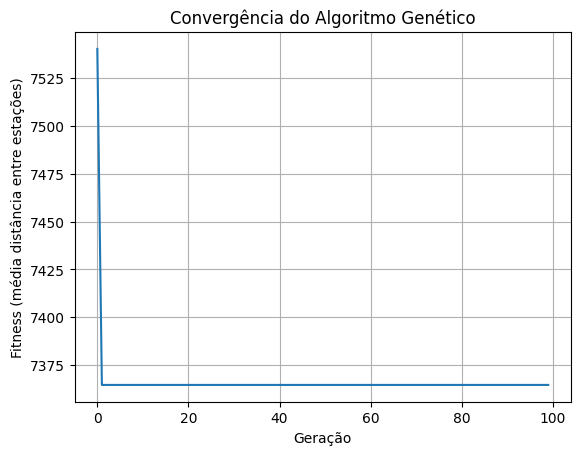

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from geopy.distance import geodesic

# ==============================================
# 1. Leitura dos dados
# ==============================================
df = pd.read_csv("./locais_candidatos.csv")

# Checar dados básicos
print("Total de locais candidatos:", len(df))
df.head()

# ==============================================
# 2. Configurações do GA
# ==============================================
NUM_ESTACOES = 10   # número de estações a posicionar
POP_SIZE = 50       # tamanho da população
NUM_GENERATIONS = 100
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.1

random.seed(42)
np.random.seed(42)

# ==============================================
# 3. Função de Avaliação (fitness)
# Objetivo: maximizar a cobertura geográfica
# ==============================================
def fitness(individuo):
    # Convertendo índices em coordenadas
    coords = [(df.loc[i, 'latitude'], df.loc[i, 'longitude']) for i in individuo]
    soma_dist = 0
    for i in range(len(coords)):
        for j in range(i+1, len(coords)):
            soma_dist += geodesic(coords[i], coords[j]).meters
    return soma_dist / (len(coords) * (len(coords)-1) / 2)  # média das distâncias

# ==============================================
# 4. Inicialização da população
# ==============================================
def inicializar_populacao():
    return [random.sample(range(len(df)), NUM_ESTACOES) for _ in range(POP_SIZE)]

# ==============================================
# 5. Seleção (torneio)
# ==============================================
def selecao(pop, scores):
    k = 3
    selecionados = random.sample(list(zip(pop, scores)), k)
    selecionados.sort(key=lambda x: x[1], reverse=True)
    return selecionados[0][0]

# ==============================================
# 6. Crossover (1 ponto)
# ==============================================
def crossover(p1, p2):
    if random.random() > CROSSOVER_RATE:
        return p1[:]
    ponto = random.randint(1, NUM_ESTACOES-1)
    filho = p1[:ponto] + [g for g in p2 if g not in p1[:ponto]]
    while len(filho) < NUM_ESTACOES:
        g = random.choice(range(len(df)))
        if g not in filho:
            filho.append(g)
    return filho

# ==============================================
# 7. Mutacao (troca de posições)
# ==============================================
def mutacao(ind):
    if random.random() < MUTATION_RATE:
        i, j = random.sample(range(NUM_ESTACOES), 2)
        ind[i], ind[j] = ind[j], ind[i]
    return ind

# ==============================================
# 8. Loop principal do GA
# ==============================================
populacao = inicializar_populacao()
historico = []

for geracao in range(NUM_GENERATIONS):
    scores = [fitness(ind) for ind in populacao]
    nova_pop = []
    for _ in range(POP_SIZE):
        p1 = selecao(populacao, scores)
        p2 = selecao(populacao, scores)
        filho = crossover(p1, p2)
        filho = mutacao(filho)
        nova_pop.append(filho)
    populacao = nova_pop
    melhor = max(scores)
    historico.append(melhor)
    print(f"Geração {geracao+1}: Melhor fitness = {melhor:.2f}")

# ==============================================
# 9. Resultados finais
# ==============================================
scores = [fitness(ind) for ind in populacao]
melhor_indice = np.argmax(scores)
melhor_solucao = populacao[melhor_indice]

print("\nMelhor conjunto de locais:")
print(df.loc[melhor_solucao])

# Gráfico de convergência
plt.plot(historico)
plt.xlabel("Geração")
plt.ylabel("Fitness (média distância entre estações)")
plt.title("Convergência do Algoritmo Genético")
plt.grid()
plt.show()


In [ ]:
import folium

# Coordenadas centrais aproximadas de Natal/RN
centro_natal = [-5.81, -35.22]
mapa = folium.Map(location=centro_natal, zoom_start=12)

# Adicionar marcadores dos melhores locais
for i, idx in enumerate(melhor_solucao):
    local = df.loc[idx]
    folium.Marker(
        location=[local['latitude'], local['longitude']],
        popup=f"{i+1}. {local['nome']} (Demanda: {local['demanda_relativa']})",
        tooltip=local['nome'],
        icon=folium.Icon(color='blue', icon='bicycle', prefix='fa')
    ).add_to(mapa)

# Exibir o mapa
mapa
